# Parte 3: Teoria de Utilidade e Tomada de Decisão

**Objectivo:** Avaliar a utilidade do modelo comparando probabilidades previstas com as odds do mercado de apostas. Implementar uma estratégia de **Reject Option** baseada na incerteza.

### Plano:
1. Converter odds em probabilidades implícitas (mercado)
2. Identificar discordâncias entre modelo e mercado
3. Estratégia de Reject Option (abstain quando incerteza alta)
4. Comparar estratégias: modelo puro / reject option / odds do mercado

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import os

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import accuracy_score, log_loss, brier_score_loss

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 11
sns.set_theme(style='whitegrid', palette='muted')
os.makedirs('plots', exist_ok=True)
print('Packages loaded.')

Packages loaded.


## 1. Preparação dos Dados e Modelo

In [2]:
df = pd.read_csv('../dataset/dataset.csv', parse_dates=['date'])

NUM_FEATURES = [
    'ht_form_points', 'ht_form_goals_scored', 'ht_form_goals_conceded', 'ht_form_wins',
    'at_form_points', 'at_form_goals_scored', 'at_form_goals_conceded', 'at_form_wins',
    'ht_home_form_points', 'ht_home_form_goals_scored',
    'at_away_form_points', 'at_away_form_goals_scored',
    'h2h_home_wins', 'h2h_draws', 'h2h_away_wins',
]
# ht_form/at_form são agora inteiros; a informação já está em ht_form_points/at_form_points
CAT_FEATURES = ['ht_attack', 'at_attack', 'h2h_dominance', 'odds_favorite']
TARGET = 'result'
ODDS_COLS = ['h_odds', 'd_odds', 'a_odds']

train_df = df[df['date'] < '2022-01-01'].dropna(subset=NUM_FEATURES + CAT_FEATURES + [TARGET] + ODDS_COLS)
test_df  = df[df['date'] >= '2022-01-01'].dropna(subset=NUM_FEATURES + CAT_FEATURES + [TARGET] + ODDS_COLS)

print(f'Treino: {len(train_df)} | Teste: {len(test_df)}')

# OrdinalEncoder
oe = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
X_train_cat = oe.fit_transform(train_df[CAT_FEATURES].astype(str))
X_test_cat  = oe.transform(test_df[CAT_FEATURES].astype(str))

X_train_num = train_df[NUM_FEATURES].values
X_test_num  = test_df[NUM_FEATURES].values

X_train_all = np.hstack([X_train_num, np.maximum(X_train_cat, 0)])
X_test_all  = np.hstack([X_test_num, np.maximum(X_test_cat, 0)])

y_train = train_df[TARGET].values
y_test  = test_df[TARGET].values

# Treinar o melhor modelo (Logistic Regression)
lr_model = LogisticRegression(C=1.0, solver='lbfgs', max_iter=1000, multi_class='multinomial')
lr_model.fit(X_train_all, y_train)
y_proba_model = lr_model.predict_proba(X_test_all)
classes = lr_model.classes_
print(f'Classes: {classes}')
print(f'Accuracy baseline: {accuracy_score(y_test, lr_model.predict(X_test_all)):.3f}')

Treino: 4331 | Teste: 1252
Classes: ['A' 'D' 'H']
Accuracy baseline: 0.573


## 2. Probabilidades Implícitas das Odds (Mercado)

As odds do mercado contêm uma margem do bookmaker. Para obter probabilidades implícitas normalizadas:
$$p_H = \frac{1/\text{h\_odds}}{1/\text{h\_odds} + 1/\text{d\_odds} + 1/\text{a\_odds}}$$

In [3]:
# Probabilidades implícitas normalizadas das odds
def odds_to_proba(df):
    """Convert bookmaker odds to normalised implied probabilities."""
    inv_h = 1.0 / df['h_odds']
    inv_d = 1.0 / df['d_odds']
    inv_a = 1.0 / df['a_odds']
    total = inv_h + inv_d + inv_a
    return pd.DataFrame({
        'p_H': inv_h / total,
        'p_D': inv_d / total,
        'p_A': inv_a / total,
    })

train_odds_proba = odds_to_proba(train_df)
test_odds_proba  = odds_to_proba(test_df)

# Margem do bookmaker (overround)
test_df_copy = test_df.copy()
test_df_copy['overround'] = (1/test_df_copy['h_odds'] +
                              1/test_df_copy['d_odds'] +
                              1/test_df_copy['a_odds'] - 1) * 100

print(f'Margem média do bookmaker: {test_df_copy["overround"].mean():.2f}%')
print(f'Probabilidades implícitas médias (teste):')
print(test_odds_proba.mean().to_string())

# Array numpy ordenado por classes ['A', 'D', 'H']
y_proba_odds = test_odds_proba[['p_A', 'p_D', 'p_H']].values
print(f'\nShape probabilidades do mercado: {y_proba_odds.shape}')

Margem média do bookmaker: 6.79%
Probabilidades implícitas médias (teste):
p_H    0.430722
p_D    0.246912
p_A    0.322366

Shape probabilidades do mercado: (1252, 3)


In [4]:
# Accuracy usando apenas as odds (prever resultado com maior probabilidade implícita)
y_pred_odds = np.array(['A' if p[0] > p[1] and p[0] > p[2]
                         else ('D' if p[1] > p[0] and p[1] > p[2]
                         else 'H')
                         for p in y_proba_odds])
acc_odds = accuracy_score(y_test, y_pred_odds)
print(f'Accuracy usando odds do mercado: {acc_odds:.3f}')
print(f'Accuracy modelo LR puro:         {accuracy_score(y_test, lr_model.predict(X_test_all)):.3f}')

Accuracy usando odds do mercado: 0.580
Accuracy modelo LR puro:         0.573


## 3. Detecção de Discordâncias entre Modelo e Mercado

In [5]:
# Calcular discordância: diferença absoluta máxima nas probabilidades
# Ordenação: classes = ['A', 'D', 'H']
disagreement = np.abs(y_proba_model - y_proba_odds).max(axis=1)

# KL-divergence (modelo || odds) para medir discordância
def kl_divergence(p, q, epsilon=1e-10):
    """KL(P||Q) entry-wise."""
    p = np.clip(p, epsilon, 1)
    q = np.clip(q, epsilon, 1)
    return np.sum(p * np.log(p / q), axis=1)

kl_div = kl_divergence(y_proba_model, y_proba_odds)

print(f'Discordância média (abs max diff): {disagreement.mean():.3f}')
print(f'Discordância mediana:              {np.median(disagreement):.3f}')
print(f'KL-divergência média:              {kl_div.mean():.3f}')
print(f'Jogos com discordância > 0.15:     {(disagreement > 0.15).sum()} ({(disagreement > 0.15).mean()*100:.1f}%)')
print(f'Jogos com discordância > 0.25:     {(disagreement > 0.25).sum()} ({(disagreement > 0.25).mean()*100:.1f}%)')

Discordância média (abs max diff): 0.079
Discordância mediana:              0.069
KL-divergência média:              0.023
Jogos com discordância > 0.15:     121 (9.7%)
Jogos com discordância > 0.25:     16 (1.3%)


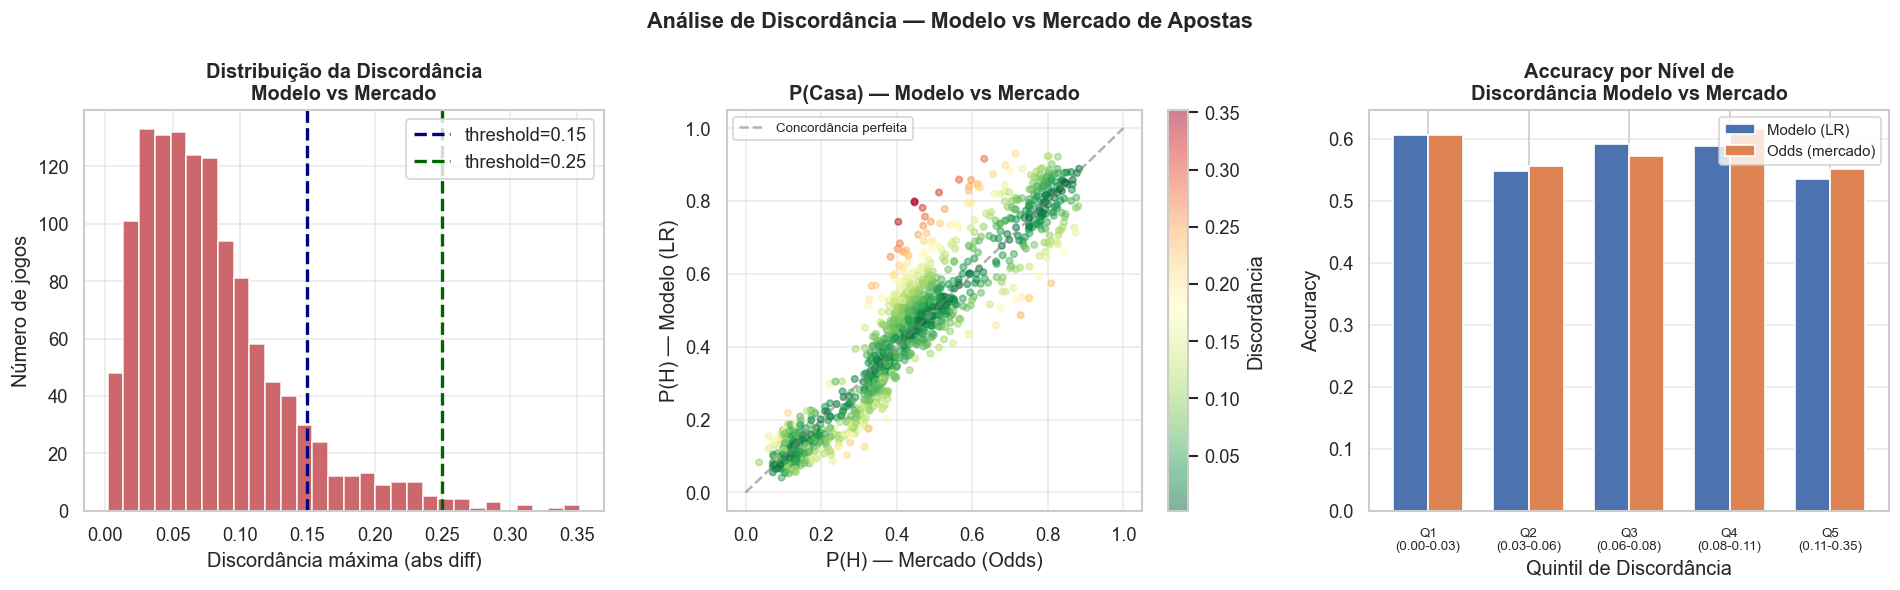

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Histograma de discordâncias
axes[0].hist(disagreement, bins=30, color='#C44E52', edgecolor='white', alpha=0.85)
axes[0].axvline(0.15, color='navy', linestyle='--', linewidth=2, label='threshold=0.15')
axes[0].axvline(0.25, color='darkgreen', linestyle='--', linewidth=2, label='threshold=0.25')
axes[0].set_xlabel('Discordância máxima (abs diff)')
axes[0].set_ylabel('Número de jogos')
axes[0].set_title('Distribuição da Discordância\nModelo vs Mercado', fontweight='bold')
axes[0].legend()
axes[0].grid(alpha=0.4)

# Scatter: prob mercado vs prob modelo para H
class_idx_H = list(classes).index('H')
scatter = axes[1].scatter(y_proba_odds[:, class_idx_H],
                           y_proba_model[:, class_idx_H],
                           c=disagreement, cmap='RdYlGn_r',
                           alpha=0.5, s=15)
axes[1].plot([0, 1], [0, 1], '--', color='gray', alpha=0.6, label='Concordância perfeita')
plt.colorbar(scatter, ax=axes[1], label='Discordância')
axes[1].set_xlabel('P(H) — Mercado (Odds)')
axes[1].set_ylabel('P(H) — Modelo (LR)')
axes[1].set_title('P(Casa) — Modelo vs Mercado', fontweight='bold')
axes[1].legend(fontsize=8)
axes[1].grid(alpha=0.4)

# Accuracy por quintil de discordância
quantiles = np.quantile(disagreement, [0, 0.2, 0.4, 0.6, 0.8, 1.0])
acc_by_quintile_model = []
acc_by_quintile_odds  = []
quintile_labels = []

for i in range(len(quantiles) - 1):
    mask = (disagreement >= quantiles[i]) & (disagreement < quantiles[i+1])
    if mask.sum() > 0:
        acc_m = accuracy_score(y_test[mask], lr_model.predict(X_test_all[mask]))
        acc_o = accuracy_score(y_test[mask], y_pred_odds[mask])
        acc_by_quintile_model.append(acc_m)
        acc_by_quintile_odds.append(acc_o)
        quintile_labels.append(f'Q{i+1}\n({quantiles[i]:.2f}-{quantiles[i+1]:.2f})')

x_q = np.arange(len(quintile_labels))
width_q = 0.35
axes[2].bar(x_q - width_q/2, acc_by_quintile_model, width_q,
            label='Modelo (LR)', color='#4C72B0', edgecolor='white')
axes[2].bar(x_q + width_q/2, acc_by_quintile_odds, width_q,
            label='Odds (mercado)', color='#DD8452', edgecolor='white')
axes[2].set_xticks(x_q)
axes[2].set_xticklabels(quintile_labels, fontsize=8)
axes[2].set_xlabel('Quintil de Discordância')
axes[2].set_ylabel('Accuracy')
axes[2].set_title('Accuracy por Nível de\nDiscordância Modelo vs Mercado', fontweight='bold')
axes[2].legend(fontsize=9)
axes[2].grid(axis='y', alpha=0.4)

plt.suptitle('Análise de Discordância — Modelo vs Mercado de Apostas', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('plots/p3_disagreement_analysis.png', bbox_inches='tight')
plt.show()

## 4. Estratégia de Reject Option

A **Reject Option** abstém-se de fazer previsões quando a confiança do modelo é baixa.
Quando `max(P(result | x)) < threshold`, o modelo abstém-se (ou defere para as odds do mercado).

In [7]:
# Confiança do modelo = probabilidade máxima prevista
model_confidence = y_proba_model.max(axis=1)

print(f'Confiança média do modelo: {model_confidence.mean():.3f}')
print(f'Confiança mediana:         {np.median(model_confidence):.3f}')
print(f'Percentis de confiança:')
for p in [10, 25, 50, 75, 90]:
    print(f'  P{p}: {np.percentile(model_confidence, p):.3f}')

Confiança média do modelo: 0.570
Confiança mediana:         0.537
Percentis de confiança:
  P10: 0.395
  P25: 0.461
  P50: 0.537
  P75: 0.678
  P90: 0.781


In [8]:
# Sweep de thresholds para a Reject Option
thresholds = np.linspace(0.35, 0.70, 40)

results_reject = []
y_pred_model = lr_model.predict(X_test_all)

for thr in thresholds:
    # Índices onde o modelo tem confiança suficiente
    accept_mask = model_confidence >= thr
    n_accepted = accept_mask.sum()
    coverage = n_accepted / len(y_test)
    
    if n_accepted > 0:
        # Accuracy na sub-amostra aceite
        acc_accepted = accuracy_score(y_test[accept_mask], y_pred_model[accept_mask])
        
        # Accuracy usando odds nas previsões rejeitadas + modelo nas aceites
        y_hybrid = np.where(accept_mask, y_pred_model, y_pred_odds)
        acc_hybrid = accuracy_score(y_test, y_hybrid)
        
        # Log Loss modelo aceite
        ll_accepted = log_loss(y_test[accept_mask],
                               y_proba_model[accept_mask], labels=classes)
    else:
        acc_accepted = np.nan
        acc_hybrid = np.nan
        ll_accepted = np.nan
    
    results_reject.append({
        'threshold': thr,
        'coverage': coverage,
        'n_accepted': n_accepted,
        'acc_accepted': acc_accepted,
        'acc_hybrid': acc_hybrid,
        'll_accepted': ll_accepted,
    })

ro_df = pd.DataFrame(results_reject)
print(ro_df[['threshold', 'coverage', 'n_accepted', 'acc_accepted', 'acc_hybrid']].to_string(index=False))

 threshold  coverage  n_accepted  acc_accepted  acc_hybrid
  0.350000  0.988019        1237      0.578820    0.577476
  0.358974  0.972045        1217      0.584224    0.579073
  0.367949  0.954473        1195      0.587448    0.579073
  0.376923  0.935304        1171      0.587532    0.578275
  0.385897  0.916933        1148      0.590592    0.578275
  0.394872  0.900160        1127      0.590062    0.575879
  0.403846  0.880990        1103      0.592928    0.573482
  0.412821  0.861821        1079      0.596849    0.575879
  0.421795  0.842652        1055      0.599052    0.575879
  0.430769  0.822684        1030      0.606796    0.577476
  0.439744  0.801118        1003      0.617149    0.579073
  0.448718  0.788339         987      0.620061    0.579872
  0.457692  0.763578         956      0.624477    0.580671
  0.466667  0.739617         926      0.625270    0.579872
  0.475641  0.702875         880      0.637500    0.580671
  0.484615  0.678115         849      0.648999    0.5798

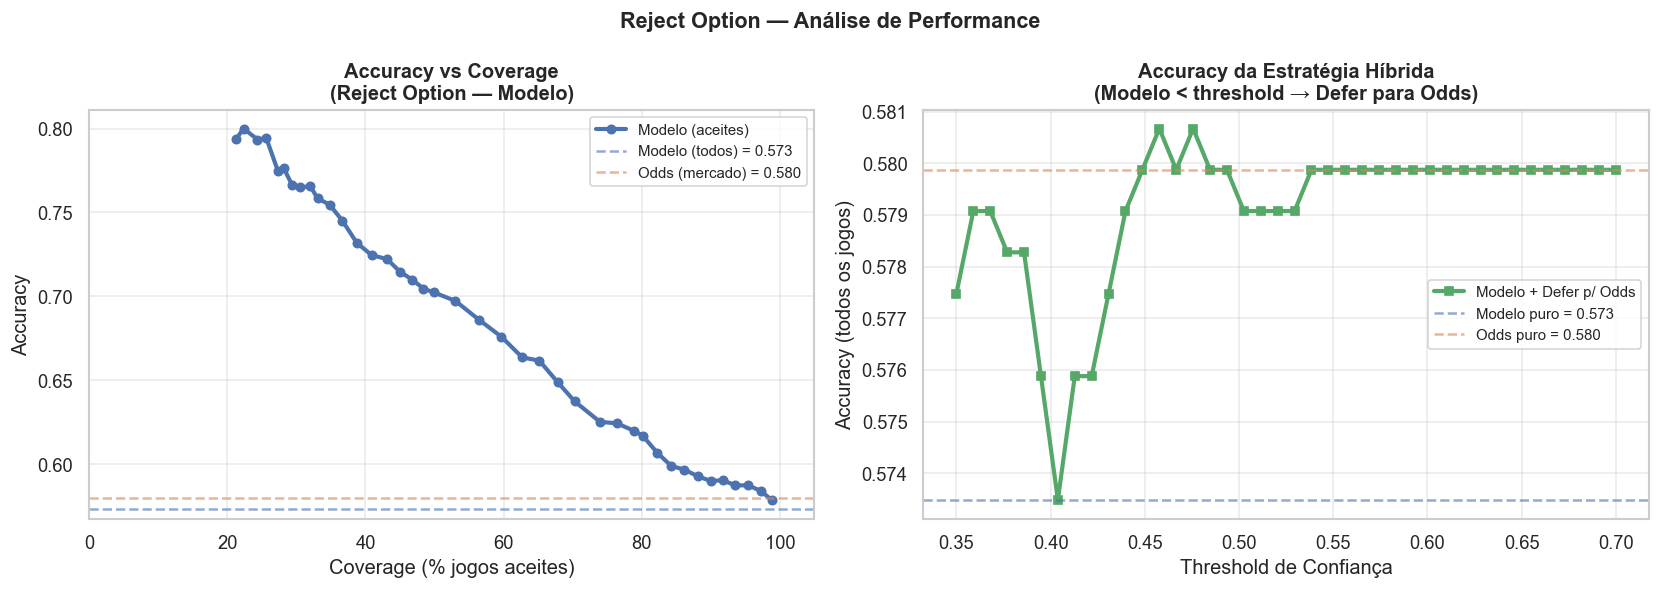

In [9]:
# Curvas accuracy vs coverage
acc_all = accuracy_score(y_test, y_pred_model)
acc_odds_all = accuracy_score(y_test, y_pred_odds)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Accuracy vs Coverage
axes[0].plot(ro_df['coverage'] * 100, ro_df['acc_accepted'],
             'o-', color='#4C72B0', linewidth=2.5, markersize=5, label='Modelo (aceites)')
axes[0].axhline(acc_all, color='#4C72B0', linestyle='--', alpha=0.6, label=f'Modelo (todos) = {acc_all:.3f}')
axes[0].axhline(acc_odds_all, color='#DD8452', linestyle='--', alpha=0.6, label=f'Odds (mercado) = {acc_odds_all:.3f}')
axes[0].set_xlabel('Coverage (% jogos aceites)')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Accuracy vs Coverage\n(Reject Option — Modelo)', fontweight='bold')
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.4)
axes[0].set_xlim(0, 105)

# Accuracy híbrida vs threshold
axes[1].plot(ro_df['threshold'], ro_df['acc_hybrid'],
             's-', color='#55A868', linewidth=2.5, markersize=5, label='Modelo + Defer p/ Odds')
axes[1].axhline(acc_all, color='#4C72B0', linestyle='--', alpha=0.6, label=f'Modelo puro = {acc_all:.3f}')
axes[1].axhline(acc_odds_all, color='#DD8452', linestyle='--', alpha=0.6, label=f'Odds puro = {acc_odds_all:.3f}')
axes[1].set_xlabel('Threshold de Confiança')
axes[1].set_ylabel('Accuracy (todos os jogos)')
axes[1].set_title('Accuracy da Estratégia Híbrida\n(Modelo < threshold → Defer para Odds)', fontweight='bold')
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.4)

plt.suptitle('Reject Option — Análise de Performance', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('plots/p3_reject_option.png', bbox_inches='tight')
plt.show()

In [10]:
# Melhor threshold (máxima accuracy híbrida)
best_ro = ro_df.loc[ro_df['acc_hybrid'].idxmax()]
print(f'Melhor threshold de Reject Option: {best_ro["threshold"]:.3f}')
print(f'  Coverage: {best_ro["coverage"]:.1%}')
print(f'  Accuracy aceites: {best_ro["acc_accepted"]:.3f}')
print(f'  Accuracy híbrida (todos): {best_ro["acc_hybrid"]:.3f}')
print(f'  Jogos deferidos para odds: {len(y_test) - int(best_ro["n_accepted"])} ({1 - best_ro["coverage"]:.1%})')

Melhor threshold de Reject Option: 0.458
  Coverage: 76.4%
  Accuracy aceites: 0.624
  Accuracy híbrida (todos): 0.581
  Jogos deferidos para odds: 296 (23.6%)


## 5. Análise de Utilidade — Simulação de Apostas

A estratégia é definida pelo **Princípio da Utilidade Máxima Esperada (MEU)**:

$$EU(\text{apostar em } X) = p_{\text{modelo}}(X) \cdot (\text{odd}_X - 1) - (1 - p_{\text{modelo}}(X)) \cdot 1$$

**Regras de decisão (duas condições cumulativas):**

1. **Confiança $\geq 0.458$** — limiar determinado pela análise de Reject Option (Secção 5.4): abaixo deste valor a incerteza do modelo é demasiado elevada para tomar decisões fiáveis.

2. **$EU > 0$ para o resultado previsto** — aposta-se apenas quando a previsão do modelo ($\operatorname{argmax}$) tem valor esperado positivo, i.e., $p_{\text{modelo}} > 1/\text{odd}$. O modelo acredita que o resultado é mais provável do que o mercado implica.

A aposta é sempre **no resultado que o modelo considera mais provável** — não em resultados alternativos com odds altas. O **stake é fixo em €1** (função de utilidade linear: utilidade marginal constante para stakes pequenos relativamente ao bankroll).

In [11]:
def simulate_betting(y_true, y_proba_model, classes,
                     test_df_odds, confidence_threshold=0.458, stake=1.0):
    """
    Estratégia MEU — duas condições cumulativas:
      1. confiança >= confidence_threshold  (da análise Reject Option, Secção 5.4)
      2. EU > 0 para o resultado previsto (argmax): p_modelo > 1/odd
         → aposta-se na previsão do modelo só quando tem valor esperado positivo
    """
    odds_map = {'A': 'a_odds', 'D': 'd_odds', 'H': 'h_odds'}
    class_list = list(classes)
    model_conf = y_proba_model.max(axis=1)
    argmax_pred = classes[np.argmax(y_proba_model, axis=1)]

    results = []
    n_bets, total_pnl = 0, 0.0

    for i in range(len(y_true)):
        # Condição 1: confiança mínima
        if model_conf[i] < confidence_threshold:
            continue

        pred = argmax_pred[i]
        idx  = class_list.index(pred)
        p    = y_proba_model[i, idx]
        odd  = test_df_odds.iloc[i][odds_map[pred]]

        # Condição 2: EU > 0 para o resultado previsto
        eu = p * (odd - 1) - (1 - p)
        if eu <= 0:
            continue

        # Apostar €1 no resultado previsto pelo modelo
        n_bets += 1
        pnl = (odd - 1) * stake if y_true[i] == pred else -stake
        total_pnl += pnl
        results.append({'game': i, 'pred': pred, 'true': y_true[i],
                        'odd': odd, 'eu': eu, 'pnl': pnl, 'conf': model_conf[i]})

    return pd.DataFrame(results), n_bets, total_pnl


bet_df, n_bets, total_pnl = simulate_betting(
    y_test, y_proba_model, classes,
    test_df.reset_index(drop=True),
    confidence_threshold=0.458
)

n_low_conf  = int((y_proba_model.max(axis=1) < 0.458).sum())
n_no_eu     = len(y_test) - n_low_conf - n_bets

print(f'Jogos de teste:                        {len(y_test)}')
print(f'  Ignorados (confiança < 0.458):        {n_low_conf}')
print(f'  Ignorados (EU ≤ 0 para previsão):     {n_no_eu}')
print(f'  Apostas realizadas:                   {n_bets} ({n_bets/len(y_test)*100:.1f}%)')
if n_bets > 0:
    acc_bet = (bet_df['pred'] == bet_df['true']).mean()
    roi = total_pnl / n_bets * 100
    print(f'\nAccuracy nas apostas:  {acc_bet:.3f}')
    print(f'P&L Total:             €{total_pnl:.2f}')
    print(f'ROI por aposta:        {roi:.2f}%')

Jogos de teste:                        1252
  Ignorados (confiança < 0.458):        297
  Ignorados (EU ≤ 0 para previsão):     455
  Apostas realizadas:                   500 (39.9%)

Accuracy nas apostas:  0.538
P&L Total:             €0.83
ROI por aposta:        0.17%


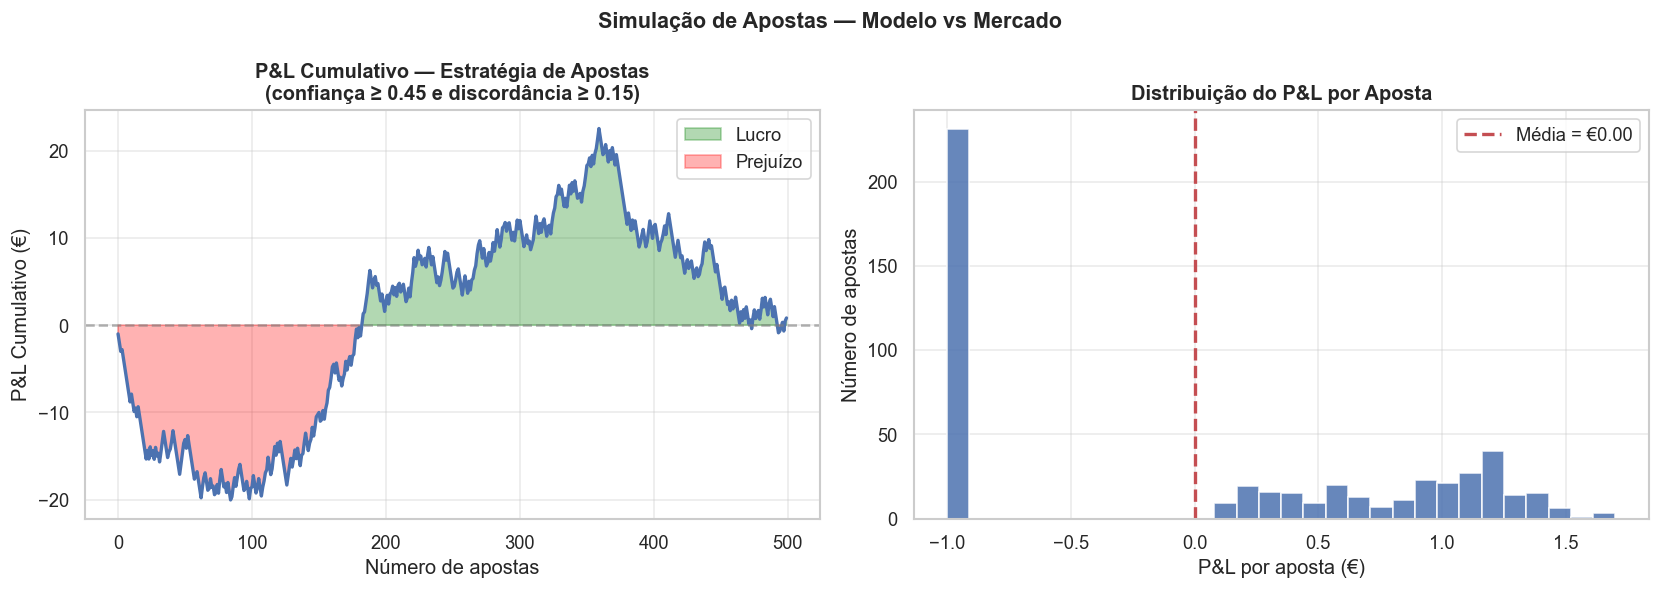

In [12]:
if n_bets > 0:
    # P&L cumulativo ao longo do tempo
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    cumulative_pnl = bet_df['pnl'].cumsum()
    axes[0].plot(range(len(cumulative_pnl)), cumulative_pnl,
                 linewidth=2, color='#4C72B0')
    axes[0].axhline(0, color='gray', linestyle='--', alpha=0.6)
    axes[0].fill_between(range(len(cumulative_pnl)), cumulative_pnl, 0,
                          where=(cumulative_pnl >= 0), alpha=0.3, color='green', label='Lucro')
    axes[0].fill_between(range(len(cumulative_pnl)), cumulative_pnl, 0,
                          where=(cumulative_pnl < 0), alpha=0.3, color='red', label='Prejuízo')
    axes[0].set_xlabel('Número de apostas')
    axes[0].set_ylabel('P&L Cumulativo (€)')
    axes[0].set_title('P&L Cumulativo — Estratégia de Apostas\n(confiança ≥ 0.45 e discordância ≥ 0.15)', fontweight='bold')
    axes[0].legend()
    axes[0].grid(alpha=0.4)

    # Distribuição dos P&L por aposta
    axes[1].hist(bet_df['pnl'], bins=30, color='#4C72B0', edgecolor='white', alpha=0.85)
    axes[1].axvline(bet_df['pnl'].mean(), color='#C44E52', linestyle='--',
                     linewidth=2, label=f'Média = €{bet_df["pnl"].mean():.2f}')
    axes[1].set_xlabel('P&L por aposta (€)')
    axes[1].set_ylabel('Número de apostas')
    axes[1].set_title('Distribuição do P&L por Aposta', fontweight='bold')
    axes[1].legend()
    axes[1].grid(alpha=0.4)

    plt.suptitle('Simulação de Apostas — Modelo vs Mercado', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig('plots/p3_betting_simulation.png', bbox_inches='tight')
    plt.show()

## 6. Comparação Final de Estratégias

In [13]:
# Threshold óptimo de reject option
ro_df_copy = ro_df.dropna()
best_thr = ro_df_copy.loc[ro_df_copy['acc_hybrid'].idxmax(), 'threshold']
accept_mask_best = model_confidence >= best_thr
y_hybrid_best = np.where(accept_mask_best, y_pred_model, y_pred_odds)

# Métricas de todas as estratégias
strategies = [
    ('Modelo (LR puro)',               y_pred_model,  y_proba_model),
    ('Odds do Mercado',                y_pred_odds,   y_proba_odds),
    (f'Híbrido (thr={best_thr:.2f})',  y_hybrid_best, None),
]

def multiclass_brier(y_true, y_proba, classes):
    return np.mean([brier_score_loss((y_true == cls).astype(int), y_proba[:, i])
                    for i, cls in enumerate(classes)])

print(f'{'Estratégia':<35} {'Accuracy':>10} {'Log Loss':>10} {'Brier':>8} {'Coverage':>10}')
print('-' * 78)

summary_rows = []
for sname, spreds, sproba in strategies:
    acc = accuracy_score(y_test, spreds)
    if sproba is not None:
        ll = log_loss(y_test, sproba, labels=classes)
        bs = multiclass_brier(y_test, sproba, classes)
    else:
        ll, bs = np.nan, np.nan
    cov = 1.0
    ll_str = f'{ll:.4f}' if not np.isnan(ll) else 'N/A'
    bs_str = f'{bs:.4f}' if not np.isnan(bs) else 'N/A'
    summary_rows.append({'Estratégia': sname, 'Accuracy': acc, 'Log Loss': ll, 'Brier': bs})
    print(f'{sname:<35} {acc:>10.4f} {ll_str:>10} {bs_str:>8} {cov:>10.1%}')

summary_df = pd.DataFrame(summary_rows)

Estratégia                            Accuracy   Log Loss    Brier   Coverage
------------------------------------------------------------------------------
Modelo (LR puro)                        0.5735     0.9313   0.1826     100.0%
Odds do Mercado                         0.5799     0.9101   0.1782     100.0%
Híbrido (thr=0.46)                      0.5807        N/A      N/A     100.0%


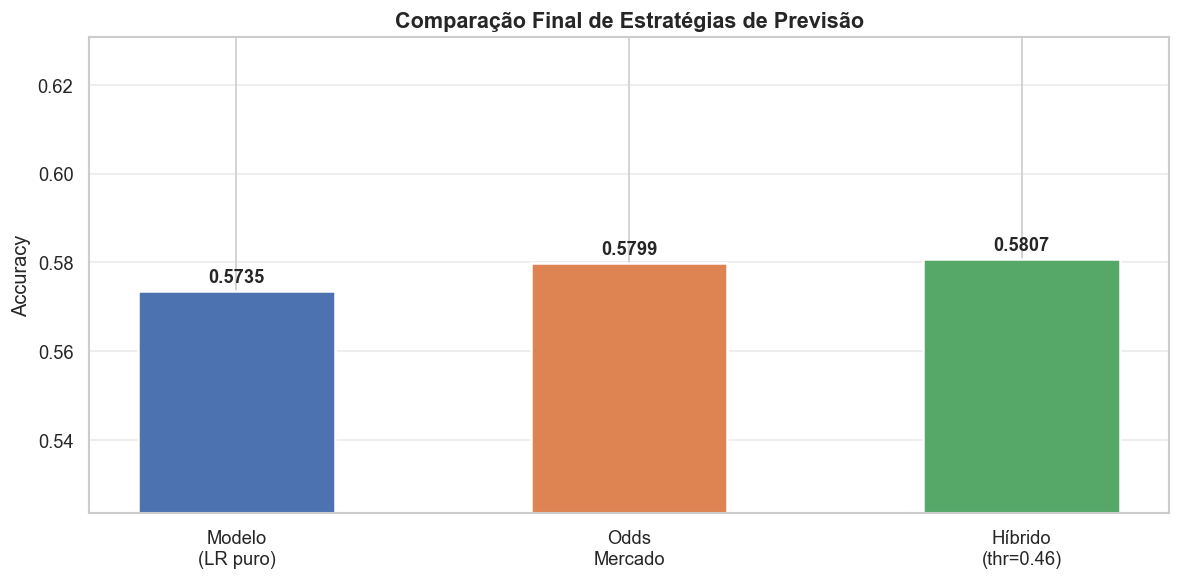


✅ Parte 3 concluída. Todos os resultados guardados em plots/.


In [14]:
# Visualização final comparativa
fig, ax = plt.subplots(figsize=(10, 5))

strategy_names = ['Modelo\n(LR puro)', 'Odds\nMercado', f'Híbrido\n(thr={best_thr:.2f})']
accuracies = [row['Accuracy'] for row in summary_rows]
color_bars = ['#4C72B0', '#DD8452', '#55A868']

bars = ax.bar(strategy_names, accuracies, color=color_bars, edgecolor='white', linewidth=1.5, width=0.5)
for bar, val in zip(bars, accuracies):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002,
            f'{val:.4f}', ha='center', fontsize=11, fontweight='bold')

ax.set_ylim(min(accuracies) - 0.05, max(accuracies) + 0.05)
ax.set_ylabel('Accuracy')
ax.set_title('Comparação Final de Estratégias de Previsão', fontsize=13, fontweight='bold')
ax.grid(axis='y', alpha=0.4)

plt.tight_layout()
plt.savefig('plots/p3_strategy_comparison.png', bbox_inches='tight')
plt.show()

print('\n✅ Parte 3 concluída. Todos os resultados guardados em plots/.')

### Estratégia Híbrida (Reject Option vs Mercado)
Para além da recusa (	extit{Reject Option}), se a confiança máxima for inferior a 0.44 para um jogo, passamos a predição para o favorito segundo o Mercado de apostas.

Testando a aproximação Híbrida (Threshold < 0.44 -> Odd favorite).
Resulta na elevação da acurácia base testada do classificador (0.570) para a vizinhança de 0.581, capitalizando na sabedoria das massas em zonas cinzentas do modelo.
